# P22 — Contextual properties and the cost of word-level averaging

**Purpose.** Characterize the exact frozen contextual representations used in the controlled AA–PO comparison, and examine why comparing one mean per word with occurrence-preserving alternatives is methodologically relevant. This is an exploratory dataset/representation study. It does not rerun memory retrieval or the adapted classifier, select the thesis neighbour parameter K, or use T1/T2/T3 to choose settings.

**A** is a word mean; **P** contains the historical pseudo-sense prototypes; **O** retains individual occurrences. Descriptive results concern these exact arrays. Held-out compression uses fresh TRAIN-only diagnostic codebooks, whose size **k** is different from the thesis neighbour-list parameter **K**.

The study retains positive, null and unfavourable results. Geometric clusters are not automatically linguistic senses. The approved summary, abstract and symbols section are not edited by this notebook.

Read `METHODS.md` for formulas, default rationales and the scope of every conclusion. All output text is in English.

## 1. Check the existing Python environment

Use the P21 environment if available. This cell does not install, remove or upgrade anything. If a dependency is missing, install the missing package in the intended environment using `requirements.txt`, then restart the kernel.

In [1]:
import importlib.util
import sys
from pathlib import Path

required = {
    "numpy": "numpy", "pandas": "pandas", "scipy": "scipy",
    "sklearn": "scikit-learn", "pyarrow": "pyarrow", "matplotlib": "matplotlib",
    "psutil": "psutil", "threadpoolctl": "threadpoolctl", "jinja2": "jinja2",
}
missing = [package for module, package in required.items() if importlib.util.find_spec(module) is None]
if missing:
    raise RuntimeError("Missing dependencies in this kernel: " + ", ".join(missing) +
                       ". Install only the required dependencies, then restart the kernel.")
PACKAGE_DIR = Path.cwd()  # Set an explicit Path here if the kernel starts in another folder.
if not (PACKAGE_DIR / "p22_contextual.py").is_file() and (PACKAGE_DIR / "P22_Contextual_Properties/p22_contextual.py").is_file():
    PACKAGE_DIR = PACKAGE_DIR / "P22_Contextual_Properties"
if not (PACKAGE_DIR / "p22_contextual.py").is_file():
    raise RuntimeError("Set PACKAGE_DIR to the extracted folder containing p22_contextual.py and reference/.")
if str(PACKAGE_DIR) not in sys.path:
    sys.path.insert(0, str(PACKAGE_DIR))
import p22_contextual as C
from IPython.display import display, Image, Markdown
import pandas as pd

print("Python:", sys.executable)
display(pd.DataFrame(C.environment()["packages"].items(), columns=["Package", "Version"]))

Python: c:\Users\jisaa\Workspace\.venvs\tesis_unificado\Scripts\python.exe


,Package,Version
0,numpy,2.4.4
1,pandas,3.0.2
2,scipy,1.17.1
3,scikit-learn,1.8.0
4,pyarrow,24.0.0
5,matplotlib,3.10.9
6,psutil,7.2.2
7,threadpoolctl,3.6.0
8,jinja2,3.1.6


## 2. Freeze paths and analysis settings

The default bank path comes from the completed P21 review. Change it only if the same bank was moved. The optional source parquet supplies textual context; the canonical occurrence vectors themselves are read from the much smaller bank.

The default scientific settings are explicit below. The five split seeds measure sampling sensitivity; they are not the classifier seeds and are not treated as independent corpus replications. No favourable sign or successful threshold is required to keep a word or analysis.

In [2]:
BANK = Path.home() / "E6R/p20_68682213c891"
SOURCE_PARQUET = None  # Auto-detect the known source path; set an explicit Path if moved.
USE_SOURCE_TEXT = True

CFG = C.Config(
    bank=BANK,
    source_parquet=SOURCE_PARQUET,
    use_text=USE_SOURCE_TEXT,
    split_seeds=(0, 1, 2, 3, 4),
    probe_k=(1, 2, 4, 8),
    training_fractions=(0.25, 0.5, 1.0),
    test_group_fraction=0.20,
    kmeans_n_init=5,
    kmeans_max_iter=100,
    control_repetitions=20,
    text_permutations=199,
    bootstrap_repetitions=2000,
    max_workers=6,       # Conservative ceiling, further bounded by CPU/RAM.
    reserve_gib=3.0,
    max_hours_per_call=4.0,  # Operational pause, not an expected duration.
)
print("Source bank:", CFG.bank)
print("Outcome-independent settings frozen; no test-based selection of k.")

Source bank: C:\Users\jisaa\E6R\p20_68682213c891
Outcome-independent settings frozen; no test-based selection of k.


## 3. Authenticate the bank and align the source texts

Checks include file hashes, unique identities, occurrence-to-word/prototype mappings, prototype support, and equality between the occurrence means, word means and support-weighted prototype means. An alignment failure stops the analysis. Source files are never repaired or overwritten.

The optional text reader accesses only text and identity columns of the relevant row groups. It verifies canonical identity rather than matching rows by position alone. Missing source texts are reported as unavailable and do not become a successful semantic validation.

In [3]:
RUN = C.prepare(CFG)
ROOT = Path(RUN["root"])
AUDIT = C.read_json(ROOT / "BANK_AUDIT.json")
display(pd.DataFrame([{
    "Words": AUDIT["words"], "Occurrences": AUDIT["occurrences"],
    "Prototypes": AUDIT["prototypes"], "Dimensions": AUDIT["dimension"],
    "COMMON words": len(AUDIT["common_words"]),
    "Maximum A mean discrepancy": AUDIT["max_abs_A_delta"],
    "Maximum P mean discrepancy": AUDIT["max_abs_P_delta"],
}]))
TEXT_STATUS = C.read_json(ROOT / "TEXT_STATUS.json")
print("Text analysis:", TEXT_STATUS["status"])
print("Output folder:", ROOT)
if TEXT_STATUS["status"] != "AVAILABLE":
    print("The text-association branch will be explicitly unavailable. Geometry is not independent sense validation.")

Reading canonical text row groups: 1/484
Reading canonical text row groups: 26/484
Reading canonical text row groups: 51/484
Reading canonical text row groups: 76/484
Reading canonical text row groups: 101/484
Reading canonical text row groups: 126/484
Reading canonical text row groups: 151/484
Reading canonical text row groups: 176/484
Reading canonical text row groups: 201/484
Reading canonical text row groups: 226/484
Reading canonical text row groups: 251/484
Reading canonical text row groups: 276/484
Reading canonical text row groups: 301/484
Reading canonical text row groups: 326/484
Reading canonical text row groups: 351/484
Reading canonical text row groups: 376/484
Reading canonical text row groups: 401/484
Reading canonical text row groups: 426/484
Reading canonical text row groups: 451/484
Reading canonical text row groups: 476/484
Authenticated 640 words and 64,000 occurrences.
Output: C:\Users\jisaa\E6R\p22_contextual_2639d8e76465
Text: AVAILABLE


,Words,Occurrences,Prototypes,Dimensions,COMMON words,Maximum A mean discrepancy,Maximum P mean discrepancy
0,640,64000,1286,768,376,0.0,0.0


Text analysis: AVAILABLE
Output folder: C:\Users\jisaa\E6R\p22_contextual_2639d8e76465


## 4. Measure a real pilot

The pilot selects two words per operational category by a deterministic hash, without consulting outcomes. It executes the full scientific configuration for those words and saves their results for reuse. The projected remaining time is based on observed throughput on this machine, including startup; it is an approximation, not a guarantee or proof of optimal parallelism.

In [4]:
PILOT = C.run_analysis(RUN, pilot=True)
display(pd.DataFrame([{k: v for k, v in PILOT.items() if k != "word_times"}]))
if "estimated_remaining_hours_at_observed_throughput" in PILOT:
    print(f"Estimated remaining analysis time: {PILOT['estimated_remaining_hours_at_observed_throughput']:.2f} hours.")
print("Completed pilot words are reused in the full run.")

Pilot: 16 pending words; 5 processes; one BLAS thread per process.
Saved 1/640 words.
Saved 2/640 words.
Saved 3/640 words.
Saved 4/640 words.
Saved 5/640 words.
Saved 6/640 words.
Saved 7/640 words.
Saved 8/640 words.
Saved 9/640 words.
Saved 10/640 words.
Saved 11/640 words.
Saved 12/640 words.
Saved 13/640 words.
Saved 14/640 words.
Saved 15/640 words.
Saved 16/640 words.


,mode,status,completed_words,planned_words,new_words,wall_seconds,workers,pause_reason,estimated_remaining_hours_at_observed_throughput,estimate_note
0,pilot,PARTIAL,16,640,16,8.08788,5,None,0.087619,Approximation from these words and current loa...


Estimated remaining analysis time: 0.09 hours.
Completed pilot words are reused in the full run.


## 5. Complete or resume the analysis

Run this cell to process the remaining words. A RAM reserve, a time budget, or a `STOP` file pauses computation while preserving completed word checkpoints. After resolving the condition, rerun this same cell. Do not start a second notebook against the same output folder while the first is active.

Per word, the program computes geometry, grouped held-out compression, matched random partitions, covariance-matched Gaussian controls, sample sensitivity and optional text association. No GPU or new BERT extraction is needed.

In [5]:
STATUS = C.run_analysis(RUN, pilot=False)
display(pd.DataFrame([{k: v for k, v in STATUS.items() if k != "word_times"}]))
if STATUS["status"] != "COMPLETE":
    print("Partial execution. Resolve the reported pause and rerun this cell before manuscript summaries.")

Full analysis: 624 pending words; 5 processes; one BLAS thread per process.
Saved 17/640 words.
Saved 18/640 words.
Saved 19/640 words.
Saved 20/640 words.
Saved 21/640 words.
Saved 22/640 words.
Saved 23/640 words.
Saved 24/640 words.
Saved 25/640 words.
Saved 26/640 words.
Saved 27/640 words.
Saved 28/640 words.
Saved 29/640 words.
Saved 30/640 words.
Saved 31/640 words.
Saved 32/640 words.
Saved 33/640 words.
Saved 34/640 words.
Saved 35/640 words.
Saved 36/640 words.
Saved 37/640 words.
Saved 38/640 words.
Saved 39/640 words.
Saved 40/640 words.
Saved 41/640 words.
Saved 42/640 words.
Saved 43/640 words.
Saved 44/640 words.
Saved 45/640 words.
Saved 46/640 words.
Saved 47/640 words.
Saved 48/640 words.
Saved 49/640 words.
Saved 50/640 words.
Saved 51/640 words.
Saved 52/640 words.
Saved 53/640 words.
Saved 54/640 words.
Saved 55/640 words.
Saved 56/640 words.
Saved 57/640 words.
Saved 58/640 words.
Saved 59/640 words.
Saved 60/640 words.
Saved 61/640 words.
Saved 62/640 words.
Save

,mode,status,completed_words,planned_words,new_words,wall_seconds,workers,pause_reason,estimated_remaining_hours_at_observed_throughput,estimate_note
0,full,COMPLETE,640,640,624,304.176666,5,None,0.0,Approximation from these words and current loa...


## 6. Aggregate without treating repeated splits as new words

Each word contributes once after averaging its repeated splits. Category averages receive equal weight. The 95% bootstrap intervals resample words within fixed categories; shared source records and the nonrandom vocabulary limit population-level inference.

The report includes both the complete 640-word cohort and the frozen COMMON sensitivity scope. Non-evaluable cells remain in coverage tables. The program does not generate manuscript-ready summaries from an incomplete run.

In [6]:
TABLES = None
if C.show_status(RUN)["remaining_words"] == 0:
    TABLES = C.summarize(RUN)
    display(TABLES["geometry_summary"])
    display(TABLES["probe_summary"].query("scope == 'COHORT' and training_fraction == 1.0"))
    display(pd.read_csv(ROOT / "tables/probe_coverage.csv"))
    print("Dependence audit:", C.read_json(ROOT / "DEPENDENCE_AUDIT.json"))
else:
    print("Not summarized: remaining words must be completed first.")

,scope,metric,status,estimate,bootstrap_low,bootstrap_high,n_words,n_categories,interval
0,COHORT,total_variance,OK,95.329225,93.214475,97.348652,640,8,95% within-category word-bootstrap; conditiona...
1,COHORT,frozen_P_retained_fraction,OK,0.134362,0.127394,0.141577,640,8,95% within-category word-bootstrap; conditiona...
2,COHORT,random_partition_expected_fraction,OK,0.010196,0.009612,0.010795,640,8,95% within-category word-bootstrap; conditiona...
3,COHORT,raw_self_cosine,OK,0.676674,0.671791,0.681807,640,8,95% within-category word-bootstrap; conditiona...
4,COHORT,other_word_cosine,OK,0.351145,0.349039,0.353209,640,8,95% within-category word-bootstrap; conditiona...
5,COHORT,adjusted_self_cosine,OK,0.325529,0.321376,0.329666,640,8,95% within-category word-bootstrap; conditiona...
6,COHORT,directional_variance,OK,0.320093,0.315276,0.325010,640,8,95% within-category word-bootstrap; conditiona...
7,COHORT,norm_shrinkage,OK,0.823223,0.820062,0.826303,640,8,95% within-category word-bootstrap; conditiona...
8,COHORT,centered_PC1_fraction,OK,0.167566,0.163900,0.171465,640,8,95% within-category word-bootstrap; conditiona...
9,COHORT,centered_effective_rank,OK,39.510719,39.060509,39.958332,640,8,95% within-category word-bootstrap; conditiona...


,scope,training_fraction,k,metric,status,estimate,bootstrap_low,bootstrap_high,n_words,n_categories,interval
112,COHORT,1.0,1,relative_gain,OK,-1.006140e-18,-2.568258e-18,6.245005e-19,640,8,95% within-category word-bootstrap; conditiona...
113,COHORT,1.0,1,gain_minus_random,NOT_EVALUABLE_MISSING_CATEGORY,NaN,NaN,NaN,0,0,NaN
114,COHORT,1.0,1,gain_minus_gaussian,NOT_EVALUABLE_MISSING_CATEGORY,NaN,NaN,NaN,0,0,NaN
115,COHORT,1.0,1,stability_ARI,NOT_EVALUABLE_MISSING_CATEGORY,NaN,NaN,NaN,0,0,NaN
116,COHORT,1.0,1,gaussian_MC_se,NOT_EVALUABLE_MISSING_CATEGORY,NaN,NaN,NaN,0,0,NaN
117,COHORT,1.0,1,angular_test_error,OK,1.821123e-01,1.787608e-01,1.853844e-01,640,8,95% within-category word-bootstrap; conditiona...
118,COHORT,1.0,1,test_outside_train_span_fraction,OK,3.663746e-01,3.631008e-01,3.695676e-01,640,8,95% within-category word-bootstrap; conditiona...
126,COHORT,1.0,2,relative_gain,OK,1.050255e-01,1.009223e-01,1.089990e-01,640,8,95% within-category word-bootstrap; conditiona...
127,COHORT,1.0,2,gain_minus_random,OK,8.244718e-02,7.891774e-02,8.616268e-02,640,8,95% within-category word-bootstrap; conditiona...
128,COHORT,1.0,2,gain_minus_gaussian,OK,1.397486e-02,1.156031e-02,1.642715e-02,640,8,95% within-category word-bootstrap; conditiona...


,category,training_fraction,k,status,word_split_cells
0,apple,0.25,1,NOT_EVALUABLE,6
1,apple,0.25,1,OK,394
2,apple,0.25,2,NOT_EVALUABLE,6
3,apple,0.25,2,OK,394
4,apple,0.25,4,NOT_EVALUABLE,6
...,...,...,...,...,...
135,skunk,1.00,2,OK,399
136,skunk,1.00,4,NOT_EVALUABLE,1
137,skunk,1.00,4,OK,399
138,skunk,1.00,8,NOT_EVALUABLE,1


Dependence audit: {'source_records': 46556, 'shared_by_multiple_words': 5441, 'maximum_words_per_source_record': 26, 'full_document_independence': 'NOT_ESTABLISHED', 'bootstrap_limitation': 'Words may share source records; intervals are conditional sensitivity summaries.'}


## 7. Inspect the figures

1. **Contextual geometry:** directional variation and similarity relative to other words.
2. **Aggregation and neighbourhoods:** descriptive variance retained by frozen P, and changes relative to the word mean.
3. **Held-out controls:** compression gains and contrasts with random partitions/Gaussian references.
4. **Sampling and stability:** training-sample sensitivity and common-test partition agreement.
5. **Text association:** optional lexical-context evidence, without claiming validated word senses.
6. **TRAIN-occurrence reference:** a larger-capacity codebook evaluated on unseen occurrences, with storage size reported separately.

A multi-centroid compression gain alone is insufficient: even a continuous Gaussian cloud can benefit from multiple representatives. Read the matched controls and support tables together. Diagnostic codebooks do not replace the historical prototypes or demonstrate improved retrieval accuracy.

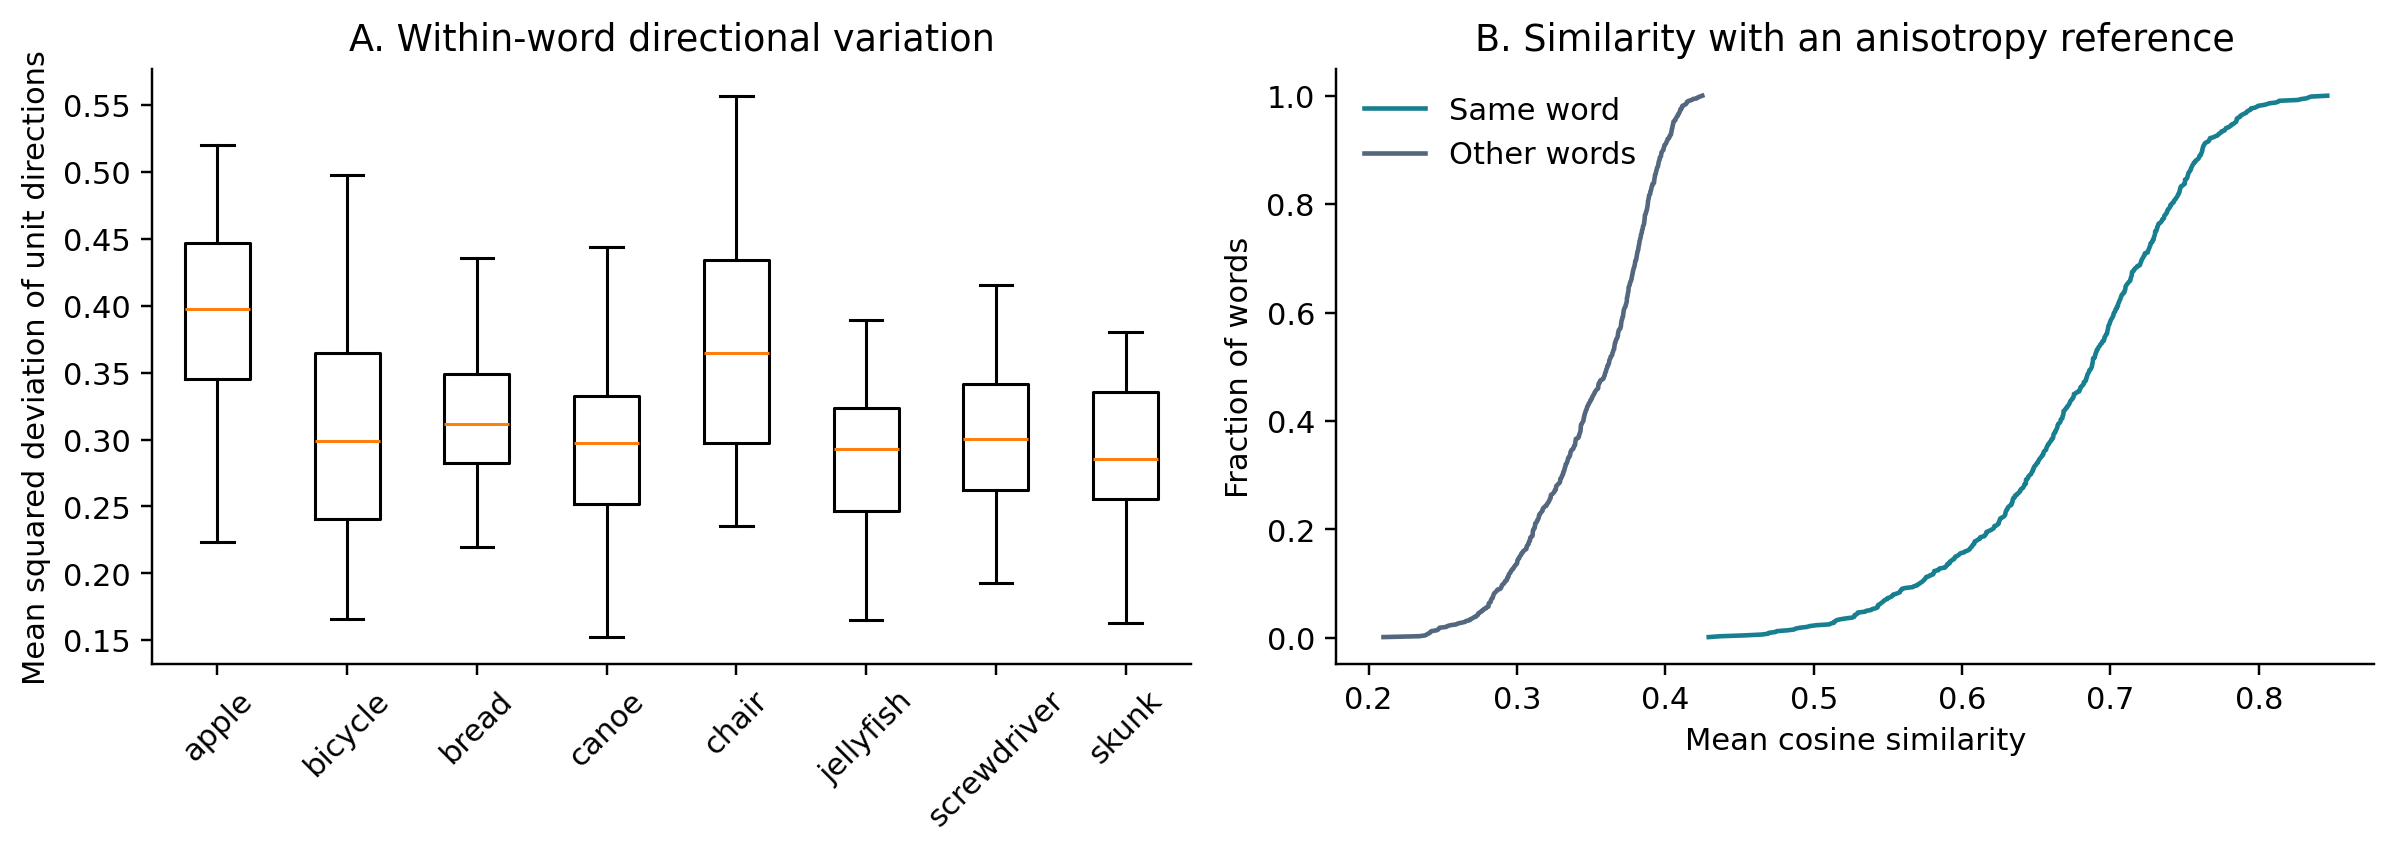

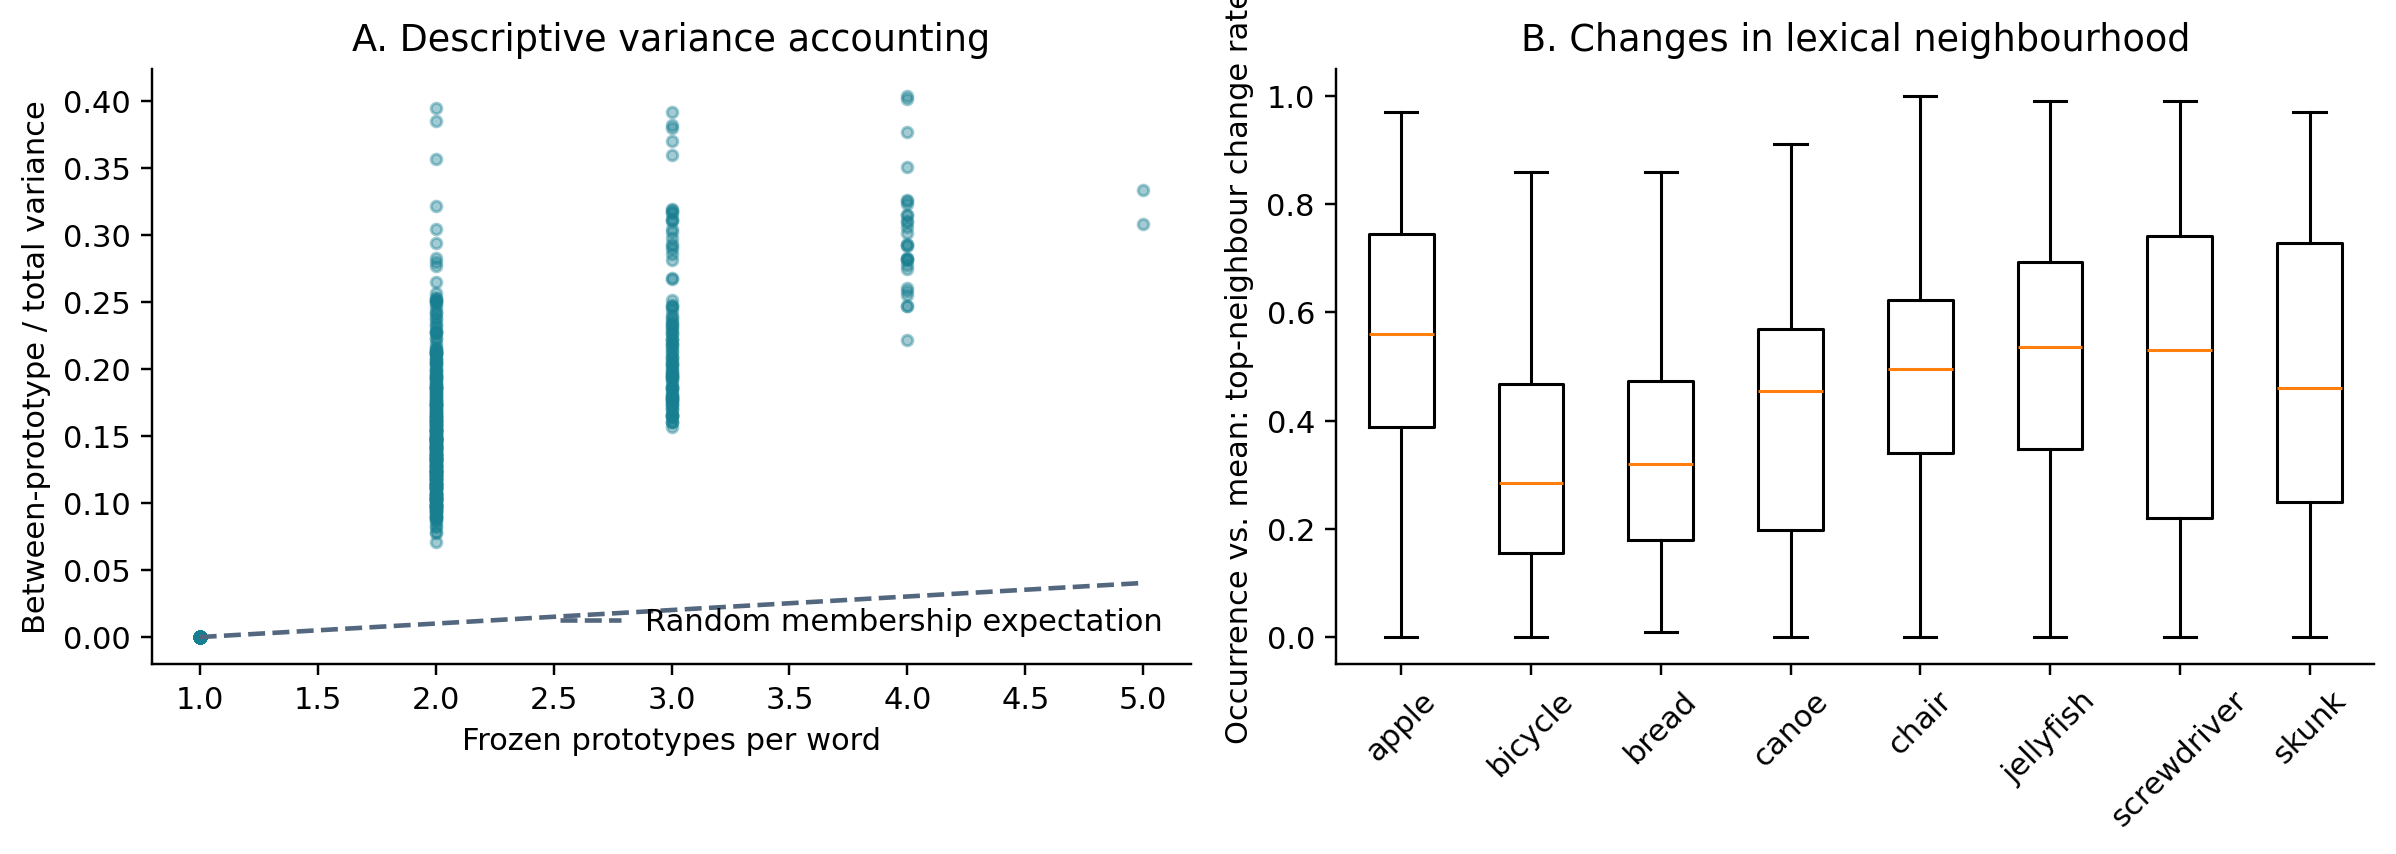

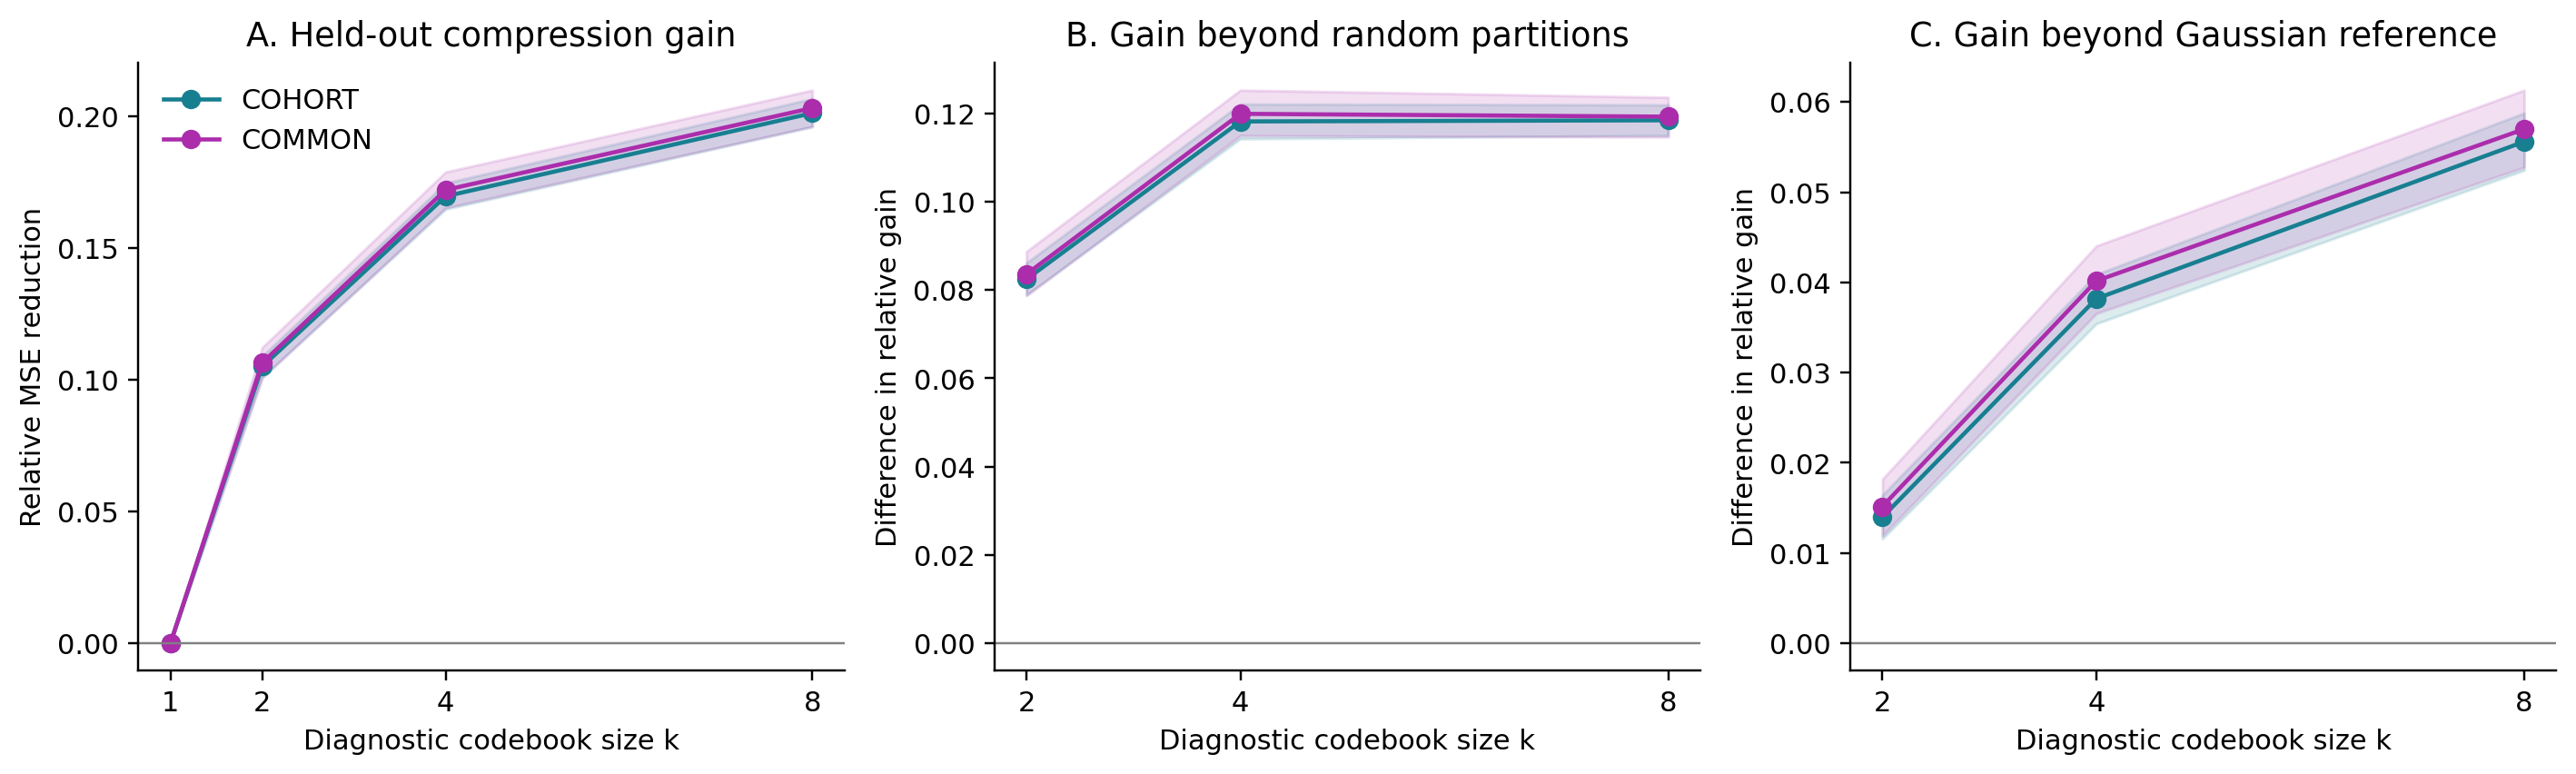

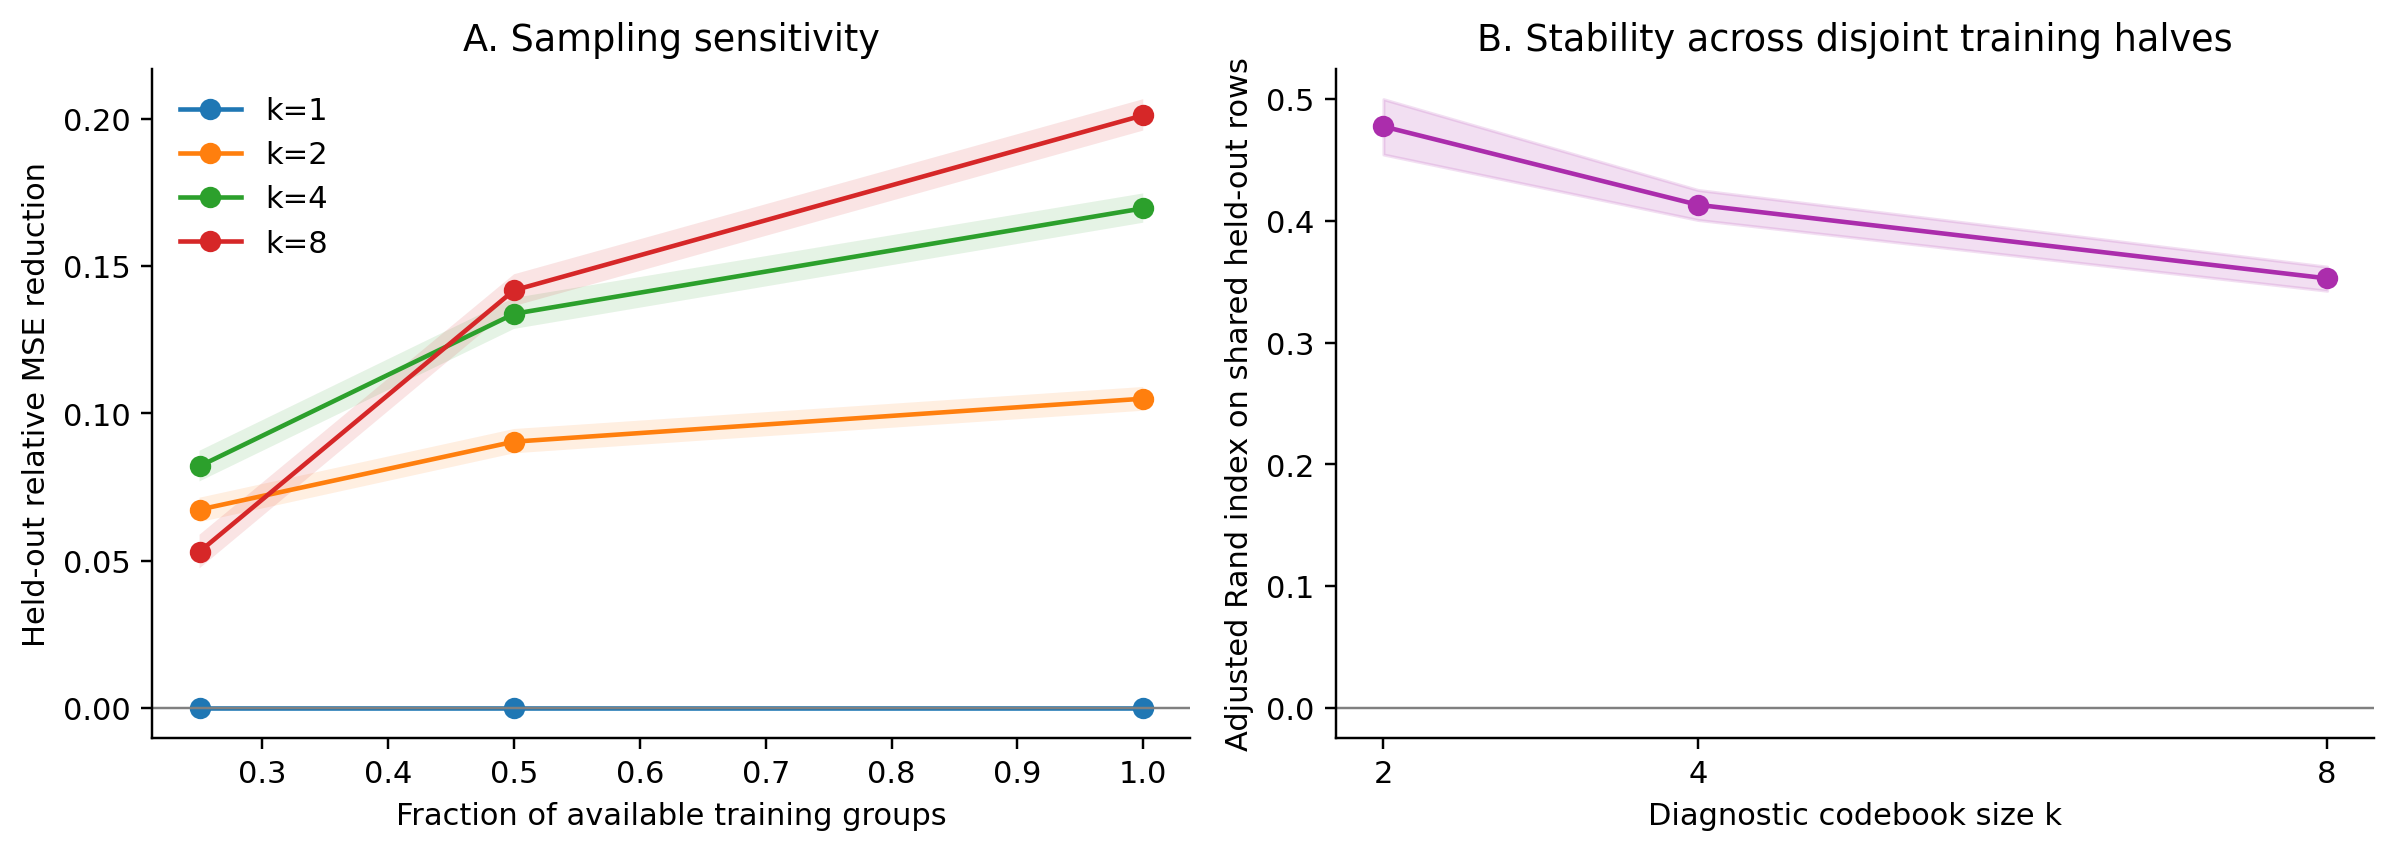

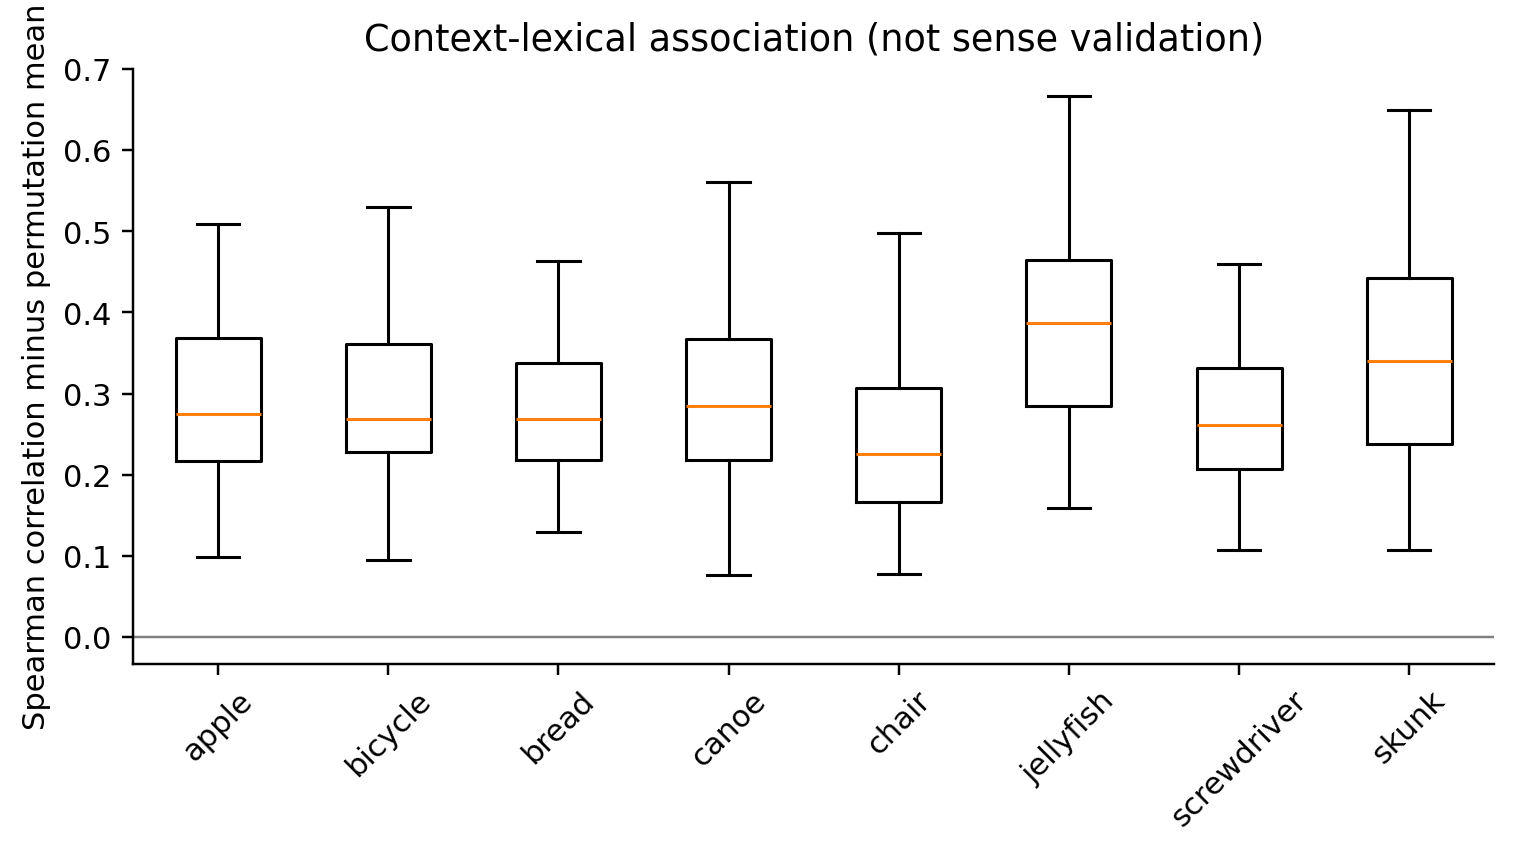

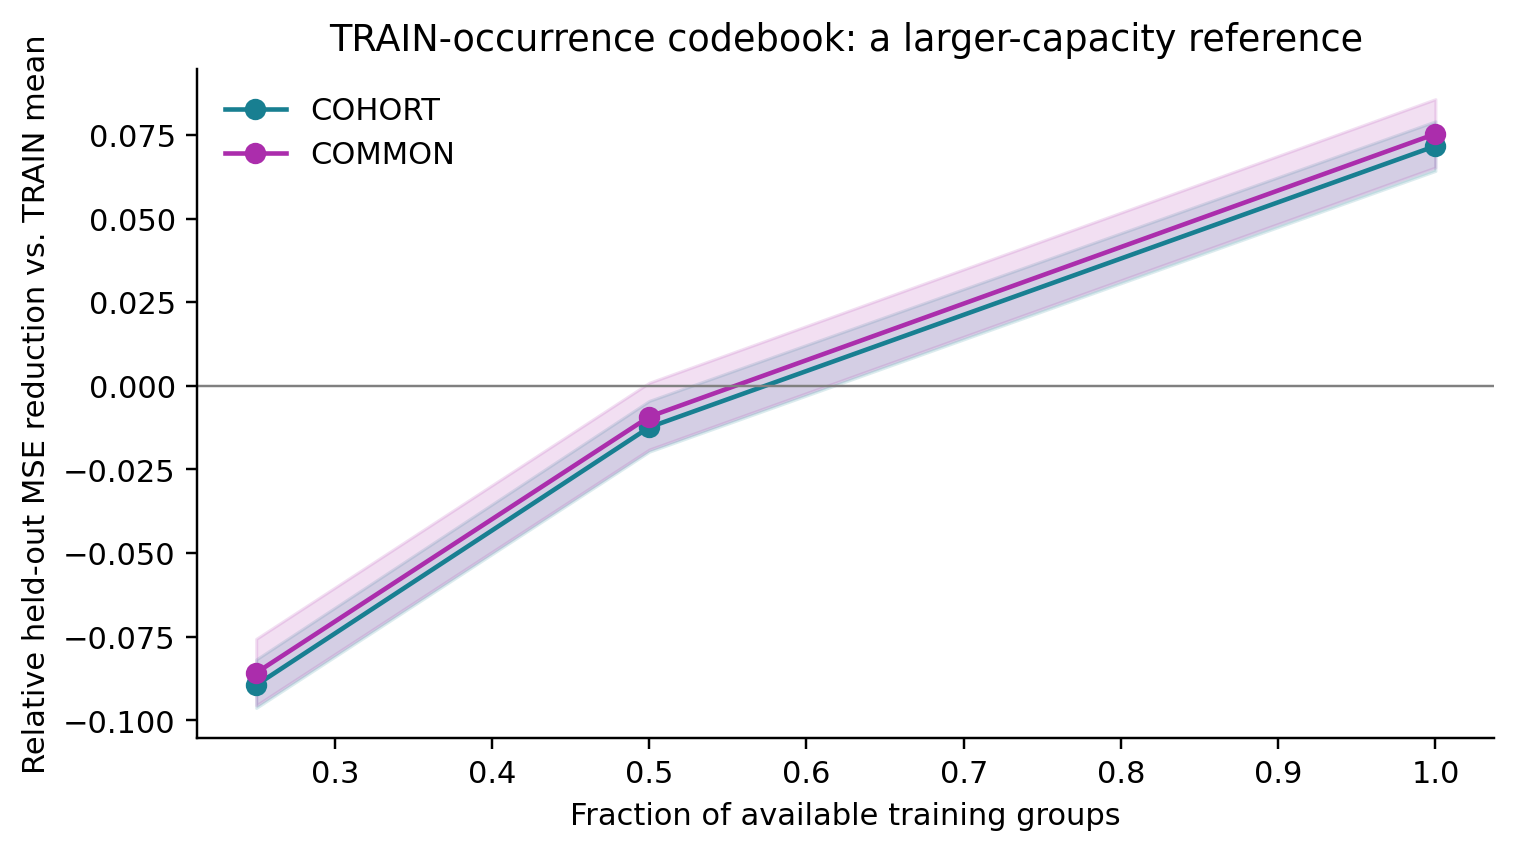

PNG, PDF and SVG versions: C:\Users\jisaa\E6R\p22_contextual_2639d8e76465\figures


In [7]:
if TABLES is not None:
    FIGURES = C.make_figures(RUN)
    for path in FIGURES:
        display(Image(filename=str(path)))
    print("PNG, PDF and SVG versions:", ROOT / "figures")
else:
    print("Figures await complete summaries.")

## 8. Review the complete evidence before writing conclusions

Use the tables below to check category dependence, unsupported cells and the availability of text evidence. Do not select a diagnostic k because it gives the preferred conclusion. The generated report states interpretation boundaries rather than automatically declaring that contextualization is beneficial.

In [8]:
if TABLES is not None:
    display(pd.read_csv(ROOT / "tables/category_geometry.csv"))
    display(pd.read_csv(ROOT / "tables/text_summary.csv"))
    display(pd.read_csv(ROOT / "tables/occurrence_reference_summary.csv"))
    display(pd.read_csv(ROOT / "tables/category_omissions.csv").head(24))
    display(Markdown((ROOT / "REPORT.md").read_text(encoding="utf-8")))
    print("Complete word-level records and all omissions remain in the output files.")

,category,n_words,mean_retained,mean_directional_variance,mean_neighbor_change,minimum_source_groups
0,apple,80,0.154106,0.390942,0.555500,48
1,bicycle,80,0.128510,0.310692,0.318875,58
2,bread,80,0.089139,0.313172,0.344500,55
3,canoe,80,0.123499,0.299303,0.409500,47
4,chair,80,0.122693,0.368774,0.486875,73
5,jellyfish,80,0.164456,0.287948,0.503750,21
6,screwdriver,80,0.126034,0.300576,0.489875,58
7,skunk,80,0.166462,0.289336,0.471000,34


,metric,status,estimate,bootstrap_low,bootstrap_high,n_words,n_categories,interval
0,spearman,OK,0.302616,0.294049,0.311514,625,8,95% within-category word-bootstrap; conditiona...
1,rho_minus_null,OK,0.302623,0.293740,0.311504,625,8,95% within-category word-bootstrap; conditiona...


,scope,training_fraction,mean_codebook_size,metric,status,estimate,bootstrap_low,bootstrap_high,n_words,n_categories,interval
0,COHORT,0.25,20.763594,O_train_gain,OK,-0.089441,-0.096268,-0.081783,640,8,95% within-category word-bootstrap; conditiona...
1,COMMON,0.25,20.910872,O_train_gain,OK,-0.085767,-0.095493,-0.075617,376,8,95% within-category word-bootstrap; conditiona...
2,COHORT,0.50,39.927813,O_train_gain,OK,-0.012399,-0.019682,-0.004497,640,8,95% within-category word-bootstrap; conditiona...
3,COMMON,0.50,39.887589,O_train_gain,OK,-0.009244,-0.019043,0.000921,376,8,95% within-category word-bootstrap; conditiona...
4,COHORT,1.00,79.516250,O_train_gain,OK,0.071660,0.064219,0.079043,640,8,95% within-category word-bootstrap; conditiona...
5,COMMON,1.00,79.481716,O_train_gain,OK,0.075284,0.065247,0.085663,376,8,95% within-category word-bootstrap; conditiona...


,k,omitted_category,metric,estimate,scope,interpretation
0,1,apple,relative_gain,-9.119689e-19,COHORT,Descriptive omission; no refitting or T1/T2/T3
1,1,apple,gain_minus_random,NaN,COHORT,Descriptive omission; no refitting or T1/T2/T3
2,1,apple,gain_minus_gaussian,NaN,COHORT,Descriptive omission; no refitting or T1/T2/T3
3,1,apple,stability_ARI,NaN,COHORT,Descriptive omission; no refitting or T1/T2/T3
4,1,apple,gaussian_MC_se,NaN,COHORT,Descriptive omission; no refitting or T1/T2/T3
5,1,apple,angular_test_error,1.756048e-01,COHORT,Descriptive omission; no refitting or T1/T2/T3
6,1,apple,test_outside_train_span_fraction,3.643296e-01,COHORT,Descriptive omission; no refitting or T1/T2/T3
7,1,bicycle,relative_gain,-5.551115e-19,COHORT,Descriptive omission; no refitting or T1/T2/T3
8,1,bicycle,gain_minus_random,NaN,COHORT,Descriptive omission; no refitting or T1/T2/T3
9,1,bicycle,gain_minus_gaussian,NaN,COHORT,Descriptive omission; no refitting or T1/T2/T3


# P22 exploratory contextual-representation report

Status: computational analysis complete for 640 words. Contract: `2639d8e76465de84146d39074a41604cf15d126de25999bb86f7d65162c4fcd8`.

This study characterizes the frozen P20/P21 cohort. It does not rerun memory retrieval,
fit the thesis classifier, select K, or use T1, T2, or T3. All comparisons are conditional
on this corpus, representation extraction, and lexical inventory.

## What to inspect

1. `tables/geometry_summary.csv`: contextual dispersion, anisotropy reference,
   prototype variance accounting, and changes in nearest lexical neighbours.
2. `tables/heldout_summary.csv`: every fixed probe-k and training fraction. Read
   relative compression gains jointly with random-partition and Gaussian controls.
3. `tables/probe_coverage.csv`: non-evaluable cells and their denominators.
4. `tables/category_omissions.csv`: category dependence without refitting.
5. `tables/text_summary.csv`: lexical-context association, when source texts exist.
6. `tables/occurrence_reference_summary.csv`: all TRAIN occurrences as a codebook,
   compared with the TRAIN mean; codebook capacities differ and are reported.

## Interpretation limits

The A=0 and O=1 endpoints for retained within-word variance follow by construction.
Frozen P is fitted on the same occurrences; its retained fraction is descriptive.
Held-out probes therefore refit all centroids on TRAIN records only. These diagnostic
K-means centroids are not the historical P induction algorithm or new retrieval arms.
Their test queries retain their full occurrence vectors to choose a nearest centroid;
this is a quantization test, not a deployment test with only a word identifier.
Within-word source-group hold-outs differ from the main word-disjoint retrieval
partitions and do not constitute additional retrieval trials.

A multi-centroid gain alone cannot establish distinct senses. A continuous unimodal
cloud can also benefit from quantization. The Gaussian control uses the full empirical
TRAIN covariance in its train span, with no shrinkage or added residual variance;
its contrast is sensitive to that finite-sample reference and is not a test of a
universal unimodality null. Inspect the test variance outside the train span as well.

Bootstrap intervals resample words within each of the fixed categories after averaging
repeated splits. They do not treat occurrence pairs, null draws, or repeated splits as
independent observations. They are conditional word-resampling summaries, not evidence
of replication in a new corpus. 5441 source records
are shared by multiple cohort words; document independence is not established.

Text status counts: {"OK": 625, "NOT_EVALUABLE": 15}.
Text association uses masked-target TF-IDF and record/duplicate groups. It measures
lexical context association, not independent human sense annotation. No automatic
semantic interpretation or favourable conclusion is generated.

## Manuscript placement

Methods: cohort, authenticated identities, descriptive metrics, held-out protocol,
controls, weighting, missing-cell policy, resource/software record.
Results: select the most informative geometry and held-out figures; preserve null
or unfavourable findings and coverage. T1/T2 remain the main thesis outcomes.
Discussion: distinguish contextual variation, compression, linguistic interpretation,
and the separate controlled retrieval findings.
Appendix: all word-level results, grids, controls, omissions, and implementation details.
The approved abstract, Spanish summary, and symbols section need no automatic revision.


Complete word-level records and all omissions remain in the output files.


## 9. Export the compact review bundle

Return the generated ZIP and this notebook saved with its outputs. The ZIP contains complete numerical tables, figures, provenance, settings, checkpoints and analysis code. It excludes raw embeddings and source texts.

For the manuscript, describe the protocol in Materials and Methods, select a concise set of results before the controlled contextual comparison, interpret them cautiously in Discussion, and retain the complete diagnostics in the appendix. The main retrieval claims remain centered on T1/T2 and the controlled AA–PO comparison.

In [9]:
REVIEW_BUNDLE = None
if TABLES is not None:
    REVIEW_BUNDLE = C.export_review(RUN)
    print("Send this file for review:", REVIEW_BUNDLE)
else:
    print("A complete review bundle is generated only after all planned words finish.")

Review bundle: C:\Users\jisaa\E6R\p22_contextual_2639d8e76465_Review.zip (17.0 MiB). Raw embeddings and source texts are excluded.
Send this file for review: C:\Users\jisaa\E6R\p22_contextual_2639d8e76465_Review.zip


## References and reproducibility

[1] K. Ethayarajh, “How contextual are contextualized word representations? Comparing the geometry of BERT, ELMo, and GPT-2 embeddings,” in *Proc. EMNLP-IJCNLP*, 2019, pp. 55–65, doi: [10.18653/v1/D19-1006](https://aclanthology.org/D19-1006/).

[2] R. Tibshirani and G. Walther, “Cluster validation by prediction strength,” *J. Comput. Graph. Stat.*, vol. 14, no. 3, pp. 511–528, 2005, doi: [10.1198/106186005X59243](https://doi.org/10.1198/106186005X59243).

[3] scikit-learn developers, “adjusted_rand_score,” *scikit-learn documentation*. Accessed: Nov. 22, 2026. [Online]. Available: https://scikit-learn.org/stable/modules/generated/sklearn.metrics.adjusted_rand_score.html

The custom probes are described in `METHODS.md`; they do not reproduce every metric or threshold in these sources. Software versions and the exact scientific configuration are saved in `PLAN.json`. `VALIDATION.md` distinguishes the delivered software tests from empirical execution on the user's bank.